# Practical 8: K-Means Clustering (Elbow and Silhouette)

**Aim:** Use K-Means clustering and find the best number of clusters with the Elbow method or the Silhouette score.

**Dataset:** Iris (150 flowers, 4 measurements). We **ignore the species** while clustering (clustering is unsupervised) and only use it at the end to check.

**Steps:** 1) Load and scale  2) Elbow method  3) Silhouette score  4) Final clusters  5) Compare with the real species

## Step 1: Load and scale

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

iris = load_iris()
X = iris.data
species = iris.target          # only used at the end, NOT for clustering

# K-Means uses distances, so scale the features
X_scaled = StandardScaler().fit_transform(X)
print(X_scaled.shape)

(150, 4)


## Step 2: Elbow method
**Inertia** = the sum of squared distances from each point to the centre of its cluster. It always decreases as k grows, so we look for the **elbow**: the k after which the drop becomes small.

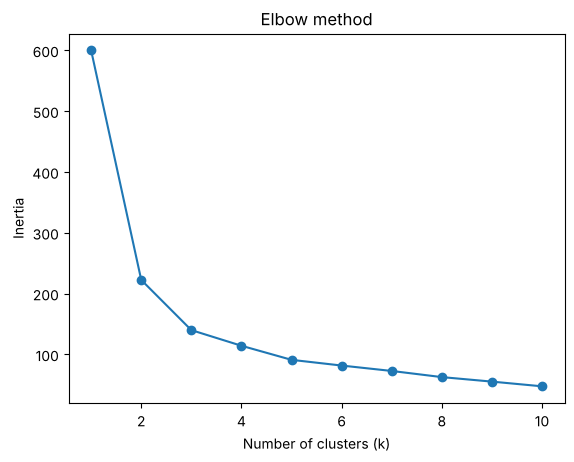

In [2]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

**How to read:** the line falls steeply at first and then flattens. The bend (the elbow) is at **k = 3**: after that, adding more clusters gives only small improvements. The elbow is a visual judgement, so it can be unclear.

## Step 3: Silhouette score
For each point it compares how close it is to its own cluster against the nearest other cluster. The score goes from -1 to +1 (higher is better). We pick the k with the **highest average score**.

Best k by silhouette: 2


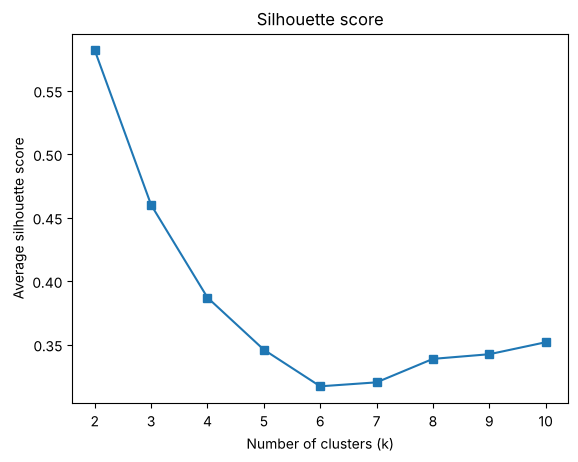

In [3]:
scores = []
k_values2 = range(2, 11)

for k in k_values2:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

best_k = list(k_values2)[np.argmax(scores)]
print("Best k by silhouette:", best_k)

plt.plot(k_values2, scores, marker="s")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.title("Silhouette score")
plt.show()

**How to read:** the best k is the highest point: here **k = 2**, not 3! Why do the two methods disagree? Two of the iris species (versicolor and virginica) overlap, so geometrically the data looks like 2 groups (setosa, and the other two together). The silhouette measures how well separated the groups are, so it prefers 2. We know there are 3 species, so we choose k = 3 (the elbow agrees). This is a very common viva question.

## Step 4: Final clusters with k = 3

Cluster sizes: [53 50 47]


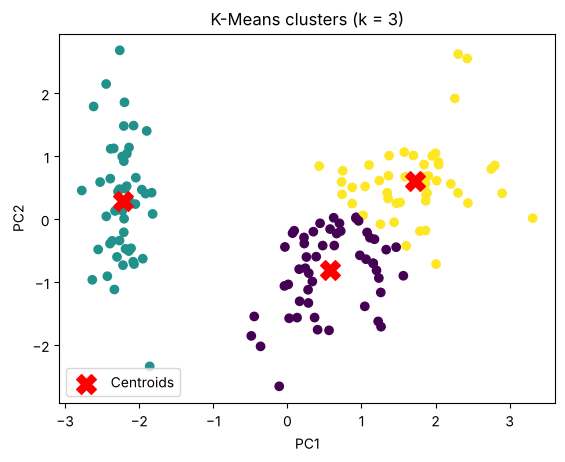

In [4]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)
print("Cluster sizes:", np.bincount(labels))

# We have 4 features, so squash them into 2 with PCA only to draw the picture
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
centres_2d = pca.transform(km.cluster_centers_)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.scatter(centres_2d[:, 0], centres_2d[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means clusters (k = 3)")
plt.legend()
plt.show()

**How to read:** each colour is a cluster and the red X marks are the **centroids** (the mean of each cluster). A flower belongs to its nearest centroid. We used PCA only to draw 4 features on a 2D page; the clustering itself used all 4.

## Step 5: Compare with the real species

In [5]:
table = pd.crosstab(pd.Series(species, name="Real species").map(dict(enumerate(iris.target_names))),
                    pd.Series(labels, name="Cluster"))
table

Cluster,0,1,2
Real species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


**How to read:** each row is a real species, each column a K-Means cluster, and the numbers are counts. Setosa falls entirely in one cluster. Versicolor and virginica are mixed across the other two clusters (about 25 of 150 flowers are in the "wrong" cluster) because those two species overlap. Cluster numbers (0, 1, 2) are just labels and need not match the species order.

## Conclusion
The elbow method suggests k = 3 and the silhouette score prefers k = 2 because two species overlap; using both with the knowledge that there are 3 species, k = 3 was chosen. Setosa is perfectly separated; the errors are only between versicolor and virginica.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is clustering?**
Grouping similar data points together without using labels (unsupervised learning).

**Q2. How does the K-Means algorithm work?**
(1) Choose k. (2) Initialise k centroids. (3) Assign every point to its nearest centroid. (4) Recompute each centroid as the mean of its points. (5) Repeat steps 3 and 4 until assignments stop changing (or max iterations).

**Q3. What is inertia / WCSS?**
Within-Cluster Sum of Squares: the total of squared distances between each point and its cluster centroid. Smaller means tighter clusters.

**Q4. What is the Elbow method?**
Plot inertia for different k and choose the k at the bend of the curve, after which improvement is marginal.

**Q5. What is the silhouette score?**
A measure of how similar a point is to its own cluster compared with other clusters, from -1 to +1. The average over all points rates the clustering.

**Q6. Elbow vs silhouette?**
Elbow is visual and subjective, and only looks at compactness. Silhouette considers compactness and separation and gives a numeric score to maximise.

**Q7. Why did the elbow and silhouette methods disagree on Iris?**
Versicolor and virginica overlap, so geometrically the data looks like 2 groups (silhouette prefers k = 2) although there are 3 species (elbow suggests 3). The methods measure different things; combine them with domain knowledge.

**Q8. Why is scaling important for K-Means?**
It uses Euclidean distance, so features with larger ranges dominate.

**Q9. What is K-Means++ initialisation?**
A smarter way to choose starting centroids, spreading them far apart. It gives faster convergence and better results than random initialisation (the default in scikit-learn).

**Q10. What is `n_init`?**
The number of times K-Means is run with different starting centroids; the run with the lowest inertia is kept.

**Q11. Limitations of K-Means?**
You must choose k in advance; sensitive to initialisation and outliers; assumes spherical, similarly-sized clusters; fails on non-convex shapes (moons, rings); numeric data only.

**Q12. Does K-Means always find the global optimum?**
No. It converges to a local optimum, so we run it several times.

**Q13. Time complexity?**
$O(n\cdot k\cdot i\cdot d)$ (n points, k clusters, i iterations, d features). It scales well to large data.

**Q14. Difference between K-Means and KNN?**
K-Means is unsupervised clustering and k is the number of clusters. KNN is a supervised classifier and k is the number of neighbours.

**Q15. How do you evaluate clustering without labels?**
Silhouette score, Davies-Bouldin index (lower is better), Calinski-Harabasz index (higher is better), inertia. With labels: Adjusted Rand Index.

**Q16. K-Means vs K-Medoids?**
K-Medoids uses actual data points as centres and is more robust to outliers; K-Means uses means.

**Q17. Hard vs soft clustering?**
K-Means is hard clustering (each point belongs to exactly one cluster). Gaussian Mixture Models do soft clustering (probabilities).

**Q18. What is a centroid?**
The mean position of all points in a cluster.

**Q19. What is the objective function K-Means minimises?**
The within-cluster sum of squared distances (inertia).

**Q20. Why does inertia always decrease as k increases?**
More centroids means every point is closer to some centroid. With k = n, inertia is zero, so we cannot just pick the minimum; we look for the elbow.

**Q22. What if the elbow is not clear?**
Use the silhouette score, the gap statistic, other indices (Davies-Bouldin), or domain knowledge.

## B. Questions about the graphs

**G1. How do you read the Elbow curve?**
X-axis is k, Y-axis is inertia. Inertia always falls as k grows; the optimal k is at the elbow, where the drop becomes slow and the curve flattens.

**G2. How do you read the silhouette plot (score vs k)?**
Choose the k with the highest average silhouette. Values near +1 mean tight, well-separated clusters; near 0 means overlapping; negative means points are probably in the wrong cluster.

**G4. What do the red X marks in the scatter plot mean?**
The centroids (the mean position of each cluster). Each point belongs to its nearest centroid.

**G5. Why are the clusters plotted using PCA?**
The data has 4 features, which cannot be drawn directly; PCA projects it to 2D for visualisation.

**G6. What does the crosstab (clusters vs species) tell you?**
How well the clusters match the true labels: setosa is perfectly isolated, versicolor and virginica are partly mixed.

## C. Code questions

**C1. What does `km.labels_` and `km.cluster_centers_` contain?**
The cluster number of every sample, and the coordinates of the centroids.

**C2. Why `random_state=42`?**
K-Means initialisation is random; the seed makes results reproducible.

**C3. Why are cluster numbers arbitrary?**
Clusters are just labels 0..k-1 assigned by the algorithm; they have no inherent meaning or order.

**C4. Why PCA after K-Means rather than before?**
We cluster in the full 4-D space to keep all information and use PCA only to draw the result.